In [2]:
import os
import pandas as pd
import bz2
import numpy as np
from glob import glob
import matplotlib.pyplot as plt
import matplotlib as mpl
import gzip
import seaborn as sns
from Bio import SeqIO, Seq
%matplotlib inline
%config InlineBackend.figure_format = 'png'
plt.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['figure.dpi']= 500

In [3]:
pools = glob('../pools/*.csv')

In [4]:
pool_data = {p.split('/')[1]:pd.read_csv(p, sep=';') for p in pools}

In [5]:
for pool in pool_data:
    pool_data[pool] = pool_data[pool].assign(AMPLICON_NAME=pool_data[pool]['AMPLICON_NAME'].apply(lambda x: x.replace(' ', '_').replace(
        '.', '_').replace('/', '_').replace('*', '_star')), AMPLICON_SEQUENCE=pool_data[pool]['AMPLICON_SEQUENCE'].apply(str.upper), 
        sgRNA_SEQUENCE=pool_data[pool]['sgRNA_SEQUENCE'].apply(lambda x: x.upper().replace(' ', '').strip(',')))

In [6]:
# define quantification window 20 nt left and right from the 3' of the guide
for pool in pool_data:
    guides_pos = []
    for i in pool_data[pool].index:
        ampl = pool_data[pool].loc[i, 'AMPLICON_SEQUENCE']
        current_pos = []
        for sgRNA in pool_data[pool].loc[i, 'sgRNA_SEQUENCE'].split(','):
            pos = max([ampl.find(sgRNA), ampl.find(str(Seq.Seq(sgRNA).reverse_complement()))])
            if pos==-1:
                print(f'Error: guide {i} ({sgRNA}) in {pool} not found in amplicon.')
            else:
                if ampl.find(sgRNA)!=-1: # guide on plus strand
                    qws = pos
                    qwe = min([pos+40, len(ampl)-1])
                    current_pos.append(f'{qws}-{qwe}')
                else:
                    qws = max([1, pos-20])
                    qwe = min([pos+20, len(ampl)-1])
                    current_pos.append(f'{qws}-{qwe}')
        guides_pos.append('_'.join(current_pos))
    pool_data[pool] = pool_data[pool].assign(QWC=guides_pos)

In [7]:
outdir = 'Bonuzzi_2026/cfg/'

In [9]:
for pool in pool_data:
    pool_data[pool].to_csv(os.path.join(outdir, pool), sep='\t', index=False)

1

## Run crispresso

```
#!/bin/bash

BASEDIR='Bonuzzi_2026'
cd $BASEDIR/output

for cfg in $BASEDIR/cfg/*.csv; do
    N=$(echo $cfg | cut -d '/' -f 11 | cut -d '.' -f 1 | cut -d '_' -f 2)
    R1=$BASEDIR/fastq/POOL-${N}_S${N}_L001_R1_001.fastq.gz
    R2=$BASEDIR/fastq/POOL-${N}_S${N}_L001_R2_001.fastq.gz
    CRISPRessoPooled -r1 $R1 -r2 $R2 -f $cfg --name POOL_$N -x /hg38/hg38_bt2 -p 64 --default_min_aln_score 10 --min_bp_quality_or_N 20 --demultiplex_only_at_amplicons
done
```

## Process output and built indel % table

Read allele frequency tables (e.g. `Alleles_frequency_table_around_sgRNA_AAGCACAGGCCTTAGCCACA.txt` ) to quantify %indels around each sgRNA.

In [11]:
indels_by_guide = {}
for pool in pool_data:
    pool_n = pool.split('_')[1].split('.')[0]
    for i in pool_data[pool].index:
        sgRNAs = pool_data[pool].loc[i, 'sgRNA_SEQUENCE'].split(',')
        name = pool_data[pool].loc[i, 'AMPLICON_NAME']
        if name not in indels_by_guide:
            indels_by_guide[name] = {}
        for sgRNA in sgRNAs:
            data_table = os.path.join(outdir.replace('cfg', 'output'), f'CRISPRessoPooled_on_POOL_{pool_n}/CRISPResso_on_{name}',
                                      f'Alleles_frequency_table_around_sgRNA_{sgRNA}.txt')
            alleles = pd.read_csv(data_table, sep='\t')
            alleles = alleles[alleles['Aligned_Sequence'].apply(lambda x: any([y!='-' for y in x]))]
            perc_indels = 100*alleles[(alleles['n_deleted']>0) | (alleles['n_inserted']>0)]['#Reads'].sum()/alleles['#Reads'].sum()
            indels_by_guide[name][sgRNA] = perc_indels

In [12]:
indels_by_guide_nt_average = {}
for sample in indels_by_guide:
    indels_by_guide_nt_average[sample] = np.mean([indels_by_guide[sample][g] for g in indels_by_guide[sample]])

In [13]:
indels_by_guide_nt_average = pd.Series(indels_by_guide_nt_average)

In [18]:
sample_sheet = pd.read_csv('../data/sample_sheet.tsv', sep='\t')

In [19]:
sample_sheet = sample_sheet.assign(**{'% indels':indels_by_guide_nt_average.loc[sample_sheet['Sample_name']].values})

### Rename samples

In [21]:
samples_new_names = {
    'Aam1':'ISAam1',
    'Dra2':'ISDra2',
    'Dra2 wRNA*':'ISDra2 reRNA*',
    'Ymu1':'ISYmu1',
    'Dge10':'ISDge10',
    'Fba1':'ISFba1'
}

In [22]:
controls = [c for c in samples_new_names.values()]

In [23]:
n = 1
for name in sample_sheet['Sample'].apply(lambda x: x.split(' ')[0]).unique():
    if name not in samples_new_names and not name.startswith('NT'):
        samples_new_names[name] = f'TnpB_{n}'
        n += 1

In [24]:
new_names = sample_sheet['Sample'].apply(lambda x: x.replace(x.split(' ')[0], samples_new_names[x.split(' ')[0]])
                             if x.split(' ')[0] in samples_new_names else x)

In [25]:
new_names = new_names.apply(lambda x: x.replace(' (paper)', ''))

In [26]:
sample_sheet = sample_sheet.assign(new_names=new_names)

In [27]:
sample_sheet = sample_sheet.sort_values(by='% indels', ascending=False)

In [28]:
NTs = sample_sheet[sample_sheet['new_names'].apply(lambda x: 'NT' in x)]
non_NTs = sample_sheet[sample_sheet['new_names'].apply(lambda x: 'NT' not in x)]

In [29]:
NTs = NTs.assign(new_names = NTs['new_names'].apply(lambda x: 'NT_'+str(int(x.replace(' ', '').replace('NT', ''))-1)))

In [30]:
NTs = NTs.sort_values(by='new_names')

In [31]:
sample_sheet = pd.concat([NTs, non_NTs.sort_values(by='new_names')])

In [32]:
final_names = []
for i in sample_sheet.index:
    if 'NT' in sample_sheet.loc[i, 'new_names'] or 'IS' in sample_sheet.loc[i, 'new_names']:
        final_names.append(sample_sheet.loc[i, 'new_names'])
    else:
        final_names.append('IS'+sample_sheet.loc[i, 'Sample'])

In [33]:
sample_sheet = sample_sheet.assign(Name=final_names)

In [38]:
all_data = sample_sheet[['Name', '% indels']]

### Plot editing values

In [39]:
all_data['ID'] = all_data['Name'].apply(lambda x: 'NT' if 'NT' in x else x.replace('_', '.'))

In [40]:
all_data['Variant'] = all_data['ID'].apply(lambda x: x.split(' ')[0])

In [41]:
pos_ctrl = {'ISDra2', 'ISAam1', 'ISYmu1', 'ISDge10', 'ISFba1'}

In [42]:
all_data['col'] = all_data['Variant'].apply(lambda x: 'lightgray' if x in pos_ctrl or x=='NT' else 'red')

In [43]:
palette = all_data[['ID', 'col']].set_index('ID')['col'].to_dict()

In [44]:
NT = all_data[all_data['Variant']=='NT']

In [45]:
P_CTRL = all_data[all_data['Variant'].apply(lambda x: x in pos_ctrl)]

In [46]:
TEST = all_data[all_data['Variant'].apply(lambda x: x not in pos_ctrl and x!='NT')]

In [47]:
P_CTRL = P_CTRL.sort_values(by='Variant')

In [48]:
TEST = TEST.sort_values(by='Variant')

In [49]:
data = pd.concat([P_CTRL, TEST])

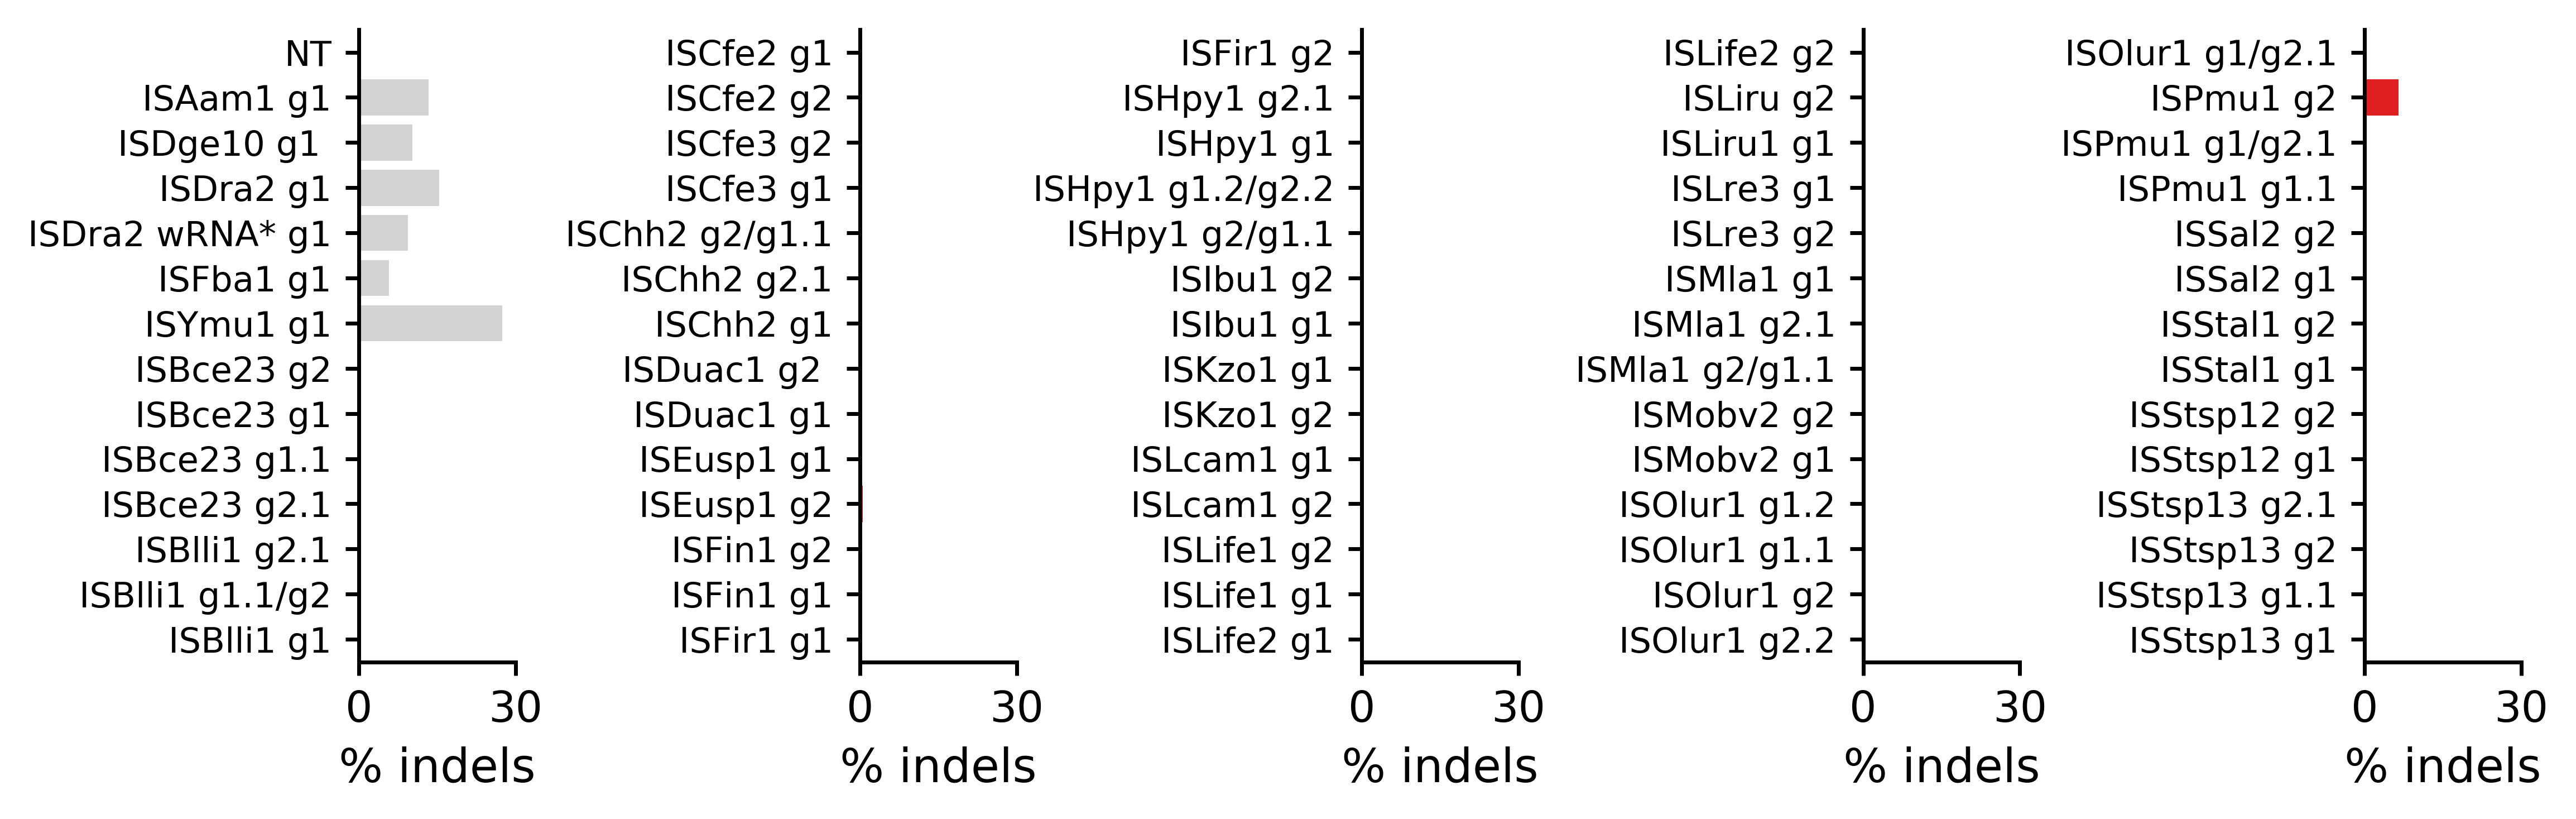

In [55]:
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(10,3))

for i in range(5):
    ax = axes[i]
    
    if i==0:
        to_plot = pd.concat([NT, data[0:13]])
    else:
        to_plot = data[i*14-1:(i+1)*14-1]

    sns.barplot(data=to_plot, y='ID', x='% indels', ax=ax, dodge=False, palette=palette)
    ax.set_xlim(0, 30)
    ax.set_xticks([0,30])

    for x in ax.get_yticklabels():
        x.set_size(9)
    ax.set_ylabel('')
    for y in ax.get_xticklabels():
        y.set_size(11)
    ax.set_xlabel('% indels', size=12)
    #ax.get_legend().remove()

    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1)
    ax.tick_params(width=1)

plt.subplots_adjust(wspace=2.2)
plt.show()

In [56]:
palette_simple = all_data[['Variant', 'col']].set_index('Variant')['col'].to_dict()

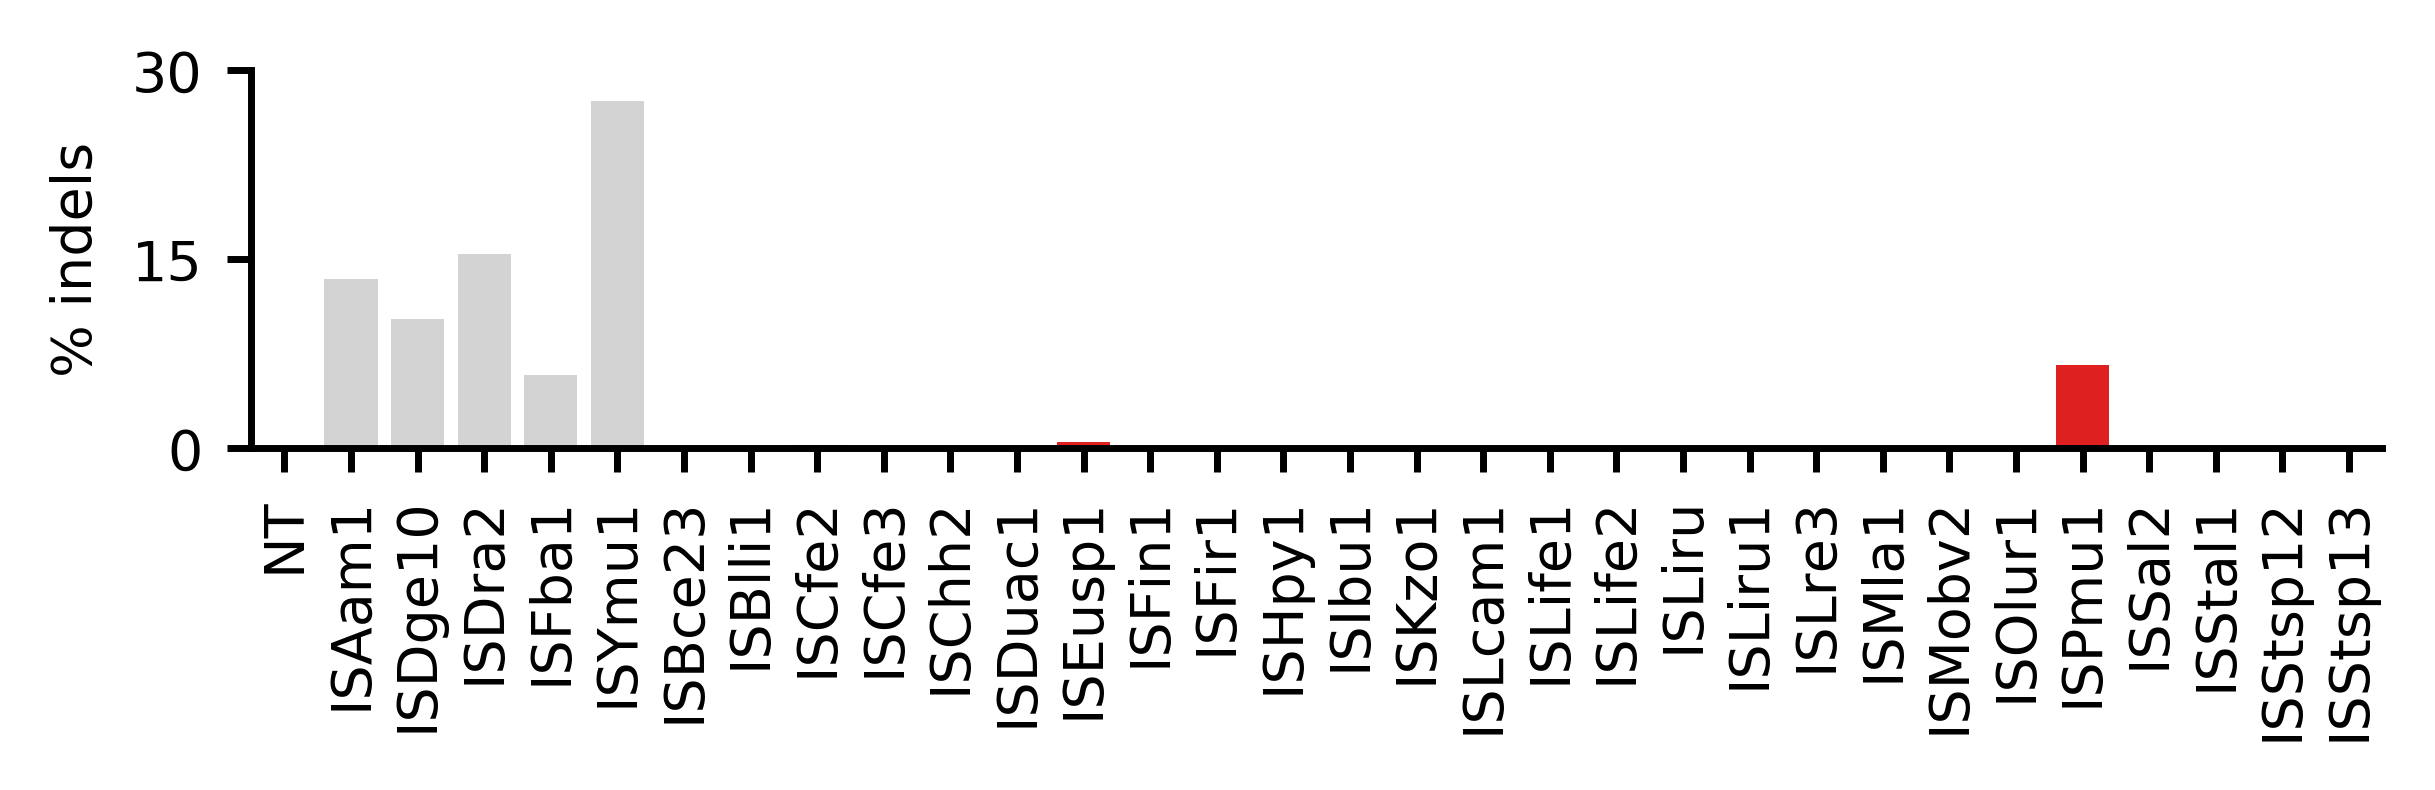

In [57]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5.5,1))
sns.barplot(data=pd.concat([NT,data]), x='Variant', y='% indels', dodge=False, ax=ax,
            estimator=max, ci=None, palette=palette_simple)

ax.set_ylim(0, 30)
ax.set_yticks([0, 15, 30])

for x in ax.get_yticklabels():
    x.set_size(8)
ax.set_xlabel('')
for y in ax.get_xticklabels():
    y.set_size(8)
    y.set_rotation(90)
ax.set_ylabel('% indels', size=8)

ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_linewidth(1)
ax.tick_params(width=1)
plt.show()